# Experiment 3 — Impact of Synthetic Library Characteristics

Giữ **k=5, m=4.422, GAM, omit bridge**. So sánh rollercoaster, wiggle, seasonal và mixed, dùng ba banks độc lập. Ba nhánh: full, **15.000 accepted curves** ngang nhau, **3.000.000 valid matching windows** ngang nhau.

Cùng **50 bang ×50 origins ×4 horizons =10.000 targets/run** của E2/E4; 36 runs, 360.000 forecasts. Đây là panel phân tích, không phải toàn bộ 112 origins của main full. Không sửa generator, không BO, không UQ. Notebook chỉ đọc kết quả. Chạy runner trước: `.venv/bin/python -u experiments/library_characteristics/experiment_3.py` (thêm `--resume` để tiếp tục).

In [1]:
from pathlib import Path
import json, sqlite3
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'experiments/library_characteristics/experiment_3.py').exists():
    if ROOT==ROOT.parent: raise RuntimeError('Không tìm thấy project root')
    ROOT=ROOT.parent
OUT=ROOT/'outputs/experiment_3'
progress=json.loads((OUT/'progress.json').read_text())
assert progress['status']=='complete' and progress['completed_runs']==36
summary=pd.read_csv(OUT/'seed_summary.csv')
scores=pd.read_csv(OUT/'scores.csv')
comparisons=pd.read_csv(OUT/'comparisons.csv')
libraries=pd.read_csv(OUT/'library_summary.csv')
morphology=pd.read_csv(OUT/'morphology.csv')
db=sqlite3.connect(f"file:{OUT/'results.sqlite'}?mode=ro",uri=True)
print(f"{progress['completed_runs']} runs, {progress['forecasts']:,} forecasts, {progress['matching_cases']:,} matching cases")
print('Algorithms: exact L1 + median future increments; no forecast hyperparameter tuning')


36 runs, 360,000 forecasts, 90,000 matching cases
Algorithms: exact L1 + median future increments; no forecast hyperparameter tuning


## Thành phần và kích thước thư viện

Full dùng toàn bộ 18.387 attempts/họ (accepted seasonal có thể ít hơn). Equal curves dùng 15.000 curves/library; mixed 5.000/họ. Equal windows dùng 3.000.000 valid windows/library; mixed 1.000.000/họ. Selection uniform, không dùng COVID outcomes, giữ source order để tie-breaking không thay đổi. Không ép thay các rejected attempts.

**C ngang nhau không bảo đảm M ngang nhau**; M ngang nhau cũng không bảo đảm số curves hữu ích ngang nhau. So sánh single với mixed trong cùng regime.

,seed,regime,library,accepted_curves,valid_windows,constant_fraction,reused
0,0,equal_curves,mixed,15000,4140510,0.136053,False
1,0,equal_curves,rollercoaster,15000,4216846,0.137050,False
2,0,equal_curves,seasonal,15000,4011138,0.126803,False
3,0,equal_curves,wiggle,15000,4205829,0.144459,False
12,1,equal_curves,mixed,15000,4176353,0.135666,False
13,1,equal_curves,rollercoaster,15000,4222750,0.137375,False
14,1,equal_curves,seasonal,15000,4015190,0.128607,False
15,1,equal_curves,wiggle,15000,4218833,0.144847,False
24,2,equal_curves,mixed,15000,4126074,0.135405,False
25,2,equal_curves,rollercoaster,15000,4196878,0.137898,False


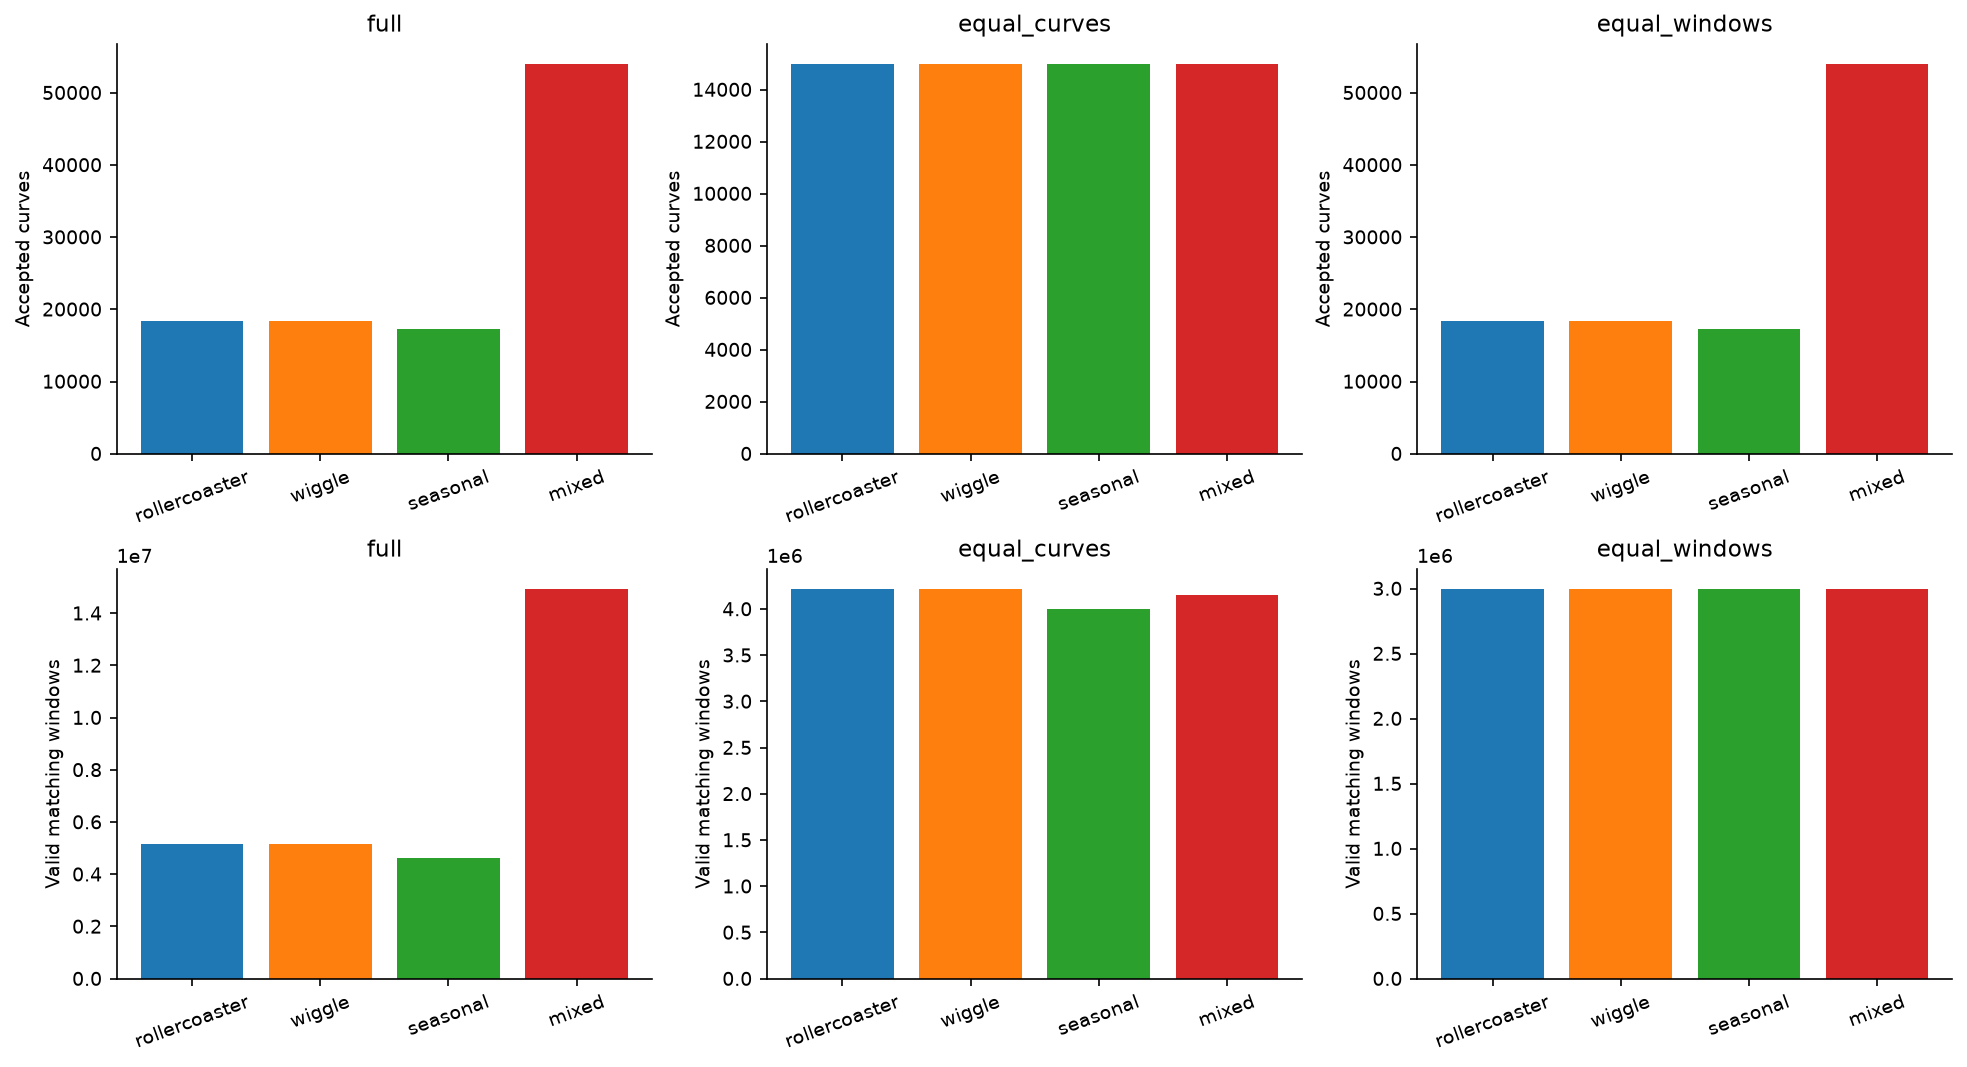

In [2]:
display(libraries[['seed','regime','library','accepted_curves','valid_windows','constant_fraction','reused']].sort_values(['regime','seed','library']))
display(Image(filename=str(OUT/'figures/size_controls.png')))


## Phân phối ba họ synthetic curves

Length, cadence, scale, số peaks và biến động được đo từ toàn bộ curves của ba banks. Giữ rule EDA: median3, prominence 10% amplitude, minimum peak distance 4 original steps. Monthly và weekly có đơn vị bước khác nhau; không coi peaks/100 monthly steps là cùng số peaks/năm với weekly. Relative volatility chuẩn hóa SD(diff) theo curve mean.

,family,cadence,scale,curves,length_mean,peaks_mean,relative_volatility_mean
0,rollercoaster,weekly,counts,27677,291.358329,3.737336,0.575354
1,rollercoaster,weekly,proportion,27484,290.499579,3.737794,0.573248
2,seasonal,monthly,counts,12972,110.749124,7.003817,1.638765
3,seasonal,monthly,proportion,12872,110.819746,6.985852,1.662332
4,seasonal,weekly,counts,12969,442.402058,9.862103,1.714917
5,seasonal,weekly,proportion,12994,441.226463,9.685212,1.875833
6,wiggle,weekly,counts,27587,291.231622,3.613867,0.609058
7,wiggle,weekly,proportion,27574,291.714762,3.623966,0.612199


mean    median       p90        p99
family        cadence                                         
rollercoaster weekly   0.574305  0.507031  0.907750   1.704700
seasonal      monthly  1.650348  0.806182  2.959412  16.675109
              weekly   1.795589  0.389816  1.715829  34.434857
wiggle        weekly   0.610629  0.533254  0.995295   1.874735

Seasonal weekly: median volatility thấp hơn nhưng đuôi phải dài, làm mean cao hơn.


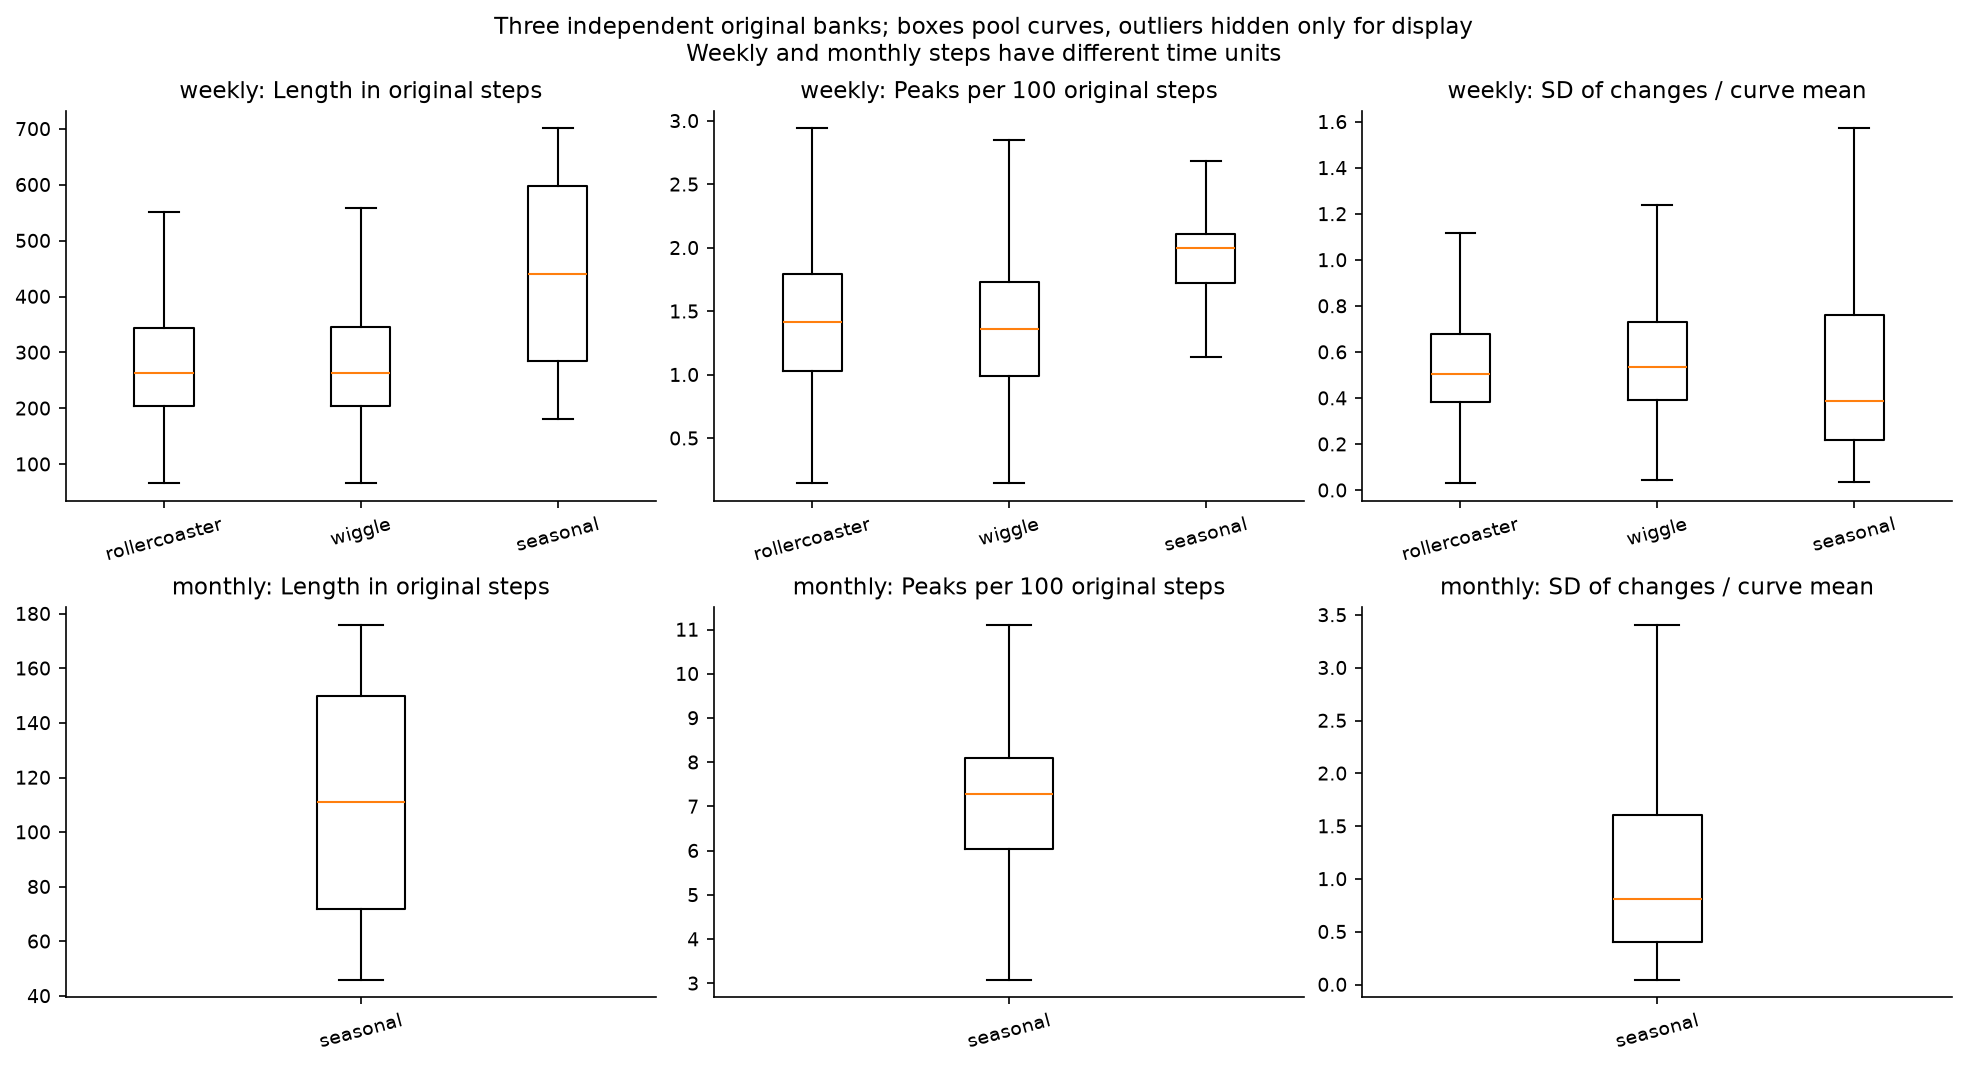

In [3]:
display(morphology.groupby(['family','cadence','scale'],as_index=False).agg(
    curves=('curves','sum'), length_mean=('length_mean','mean'), peaks_mean=('peaks_mean','mean'),
    relative_volatility_mean=('relative_volatility_mean','mean')))
vol=pd.read_sql_query('SELECT family,cadence,relative_volatility FROM curve_stats',db)
display(vol.groupby(['family','cadence']).relative_volatility.agg(
    mean='mean',median='median',p90=lambda s:s.quantile(.9),p99=lambda s:s.quantile(.99)))
print('Seasonal weekly: median volatility thấp hơn nhưng đuôi phải dài, làm mean cao hơn.')
display(Image(filename=str(OUT/'figures/curve_distributions.png')))


## Forecast accuracy và variability across seeds

MAE/RMSE tính riêng seed rồi lấy mean và sample SD. Mean RMSE không phải pooled RMSE. Ba seeds chỉ mô tả các banks đã chạy; trong hai regimes subsampling, variability còn chứa RNG của subset, chưa tách thành phần này khỏi generator RNG. Không tuning cấu hình dựa trên test results.

,regime,library,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,normalized_MAE_mean
9,equal_curves,mixed,5390.645117,10.320199,21100.479678,64.644098,0.717967
22,equal_curves,rollercoaster,5435.431067,7.810905,21018.986431,24.792700,0.738340
35,equal_curves,seasonal,5320.623583,20.209397,20947.039097,144.165078,0.696975
48,equal_curves,wiggle,5440.280200,7.336711,21206.555978,30.696256,0.720100
61,equal_windows,mixed,5419.464983,1.237966,21295.796940,41.857317,0.705718
74,equal_windows,rollercoaster,5463.741267,6.129998,21224.899058,37.557390,0.723936
87,equal_windows,seasonal,5353.254865,4.598801,21149.185783,86.316460,0.690588
100,equal_windows,wiggle,5470.097617,5.993241,21433.951727,14.498445,0.710032
113,full,mixed,5309.158950,2.369730,20634.964142,12.612493,0.739544
126,full,rollercoaster,5422.553583,9.400987,20928.621770,24.540557,0.745265


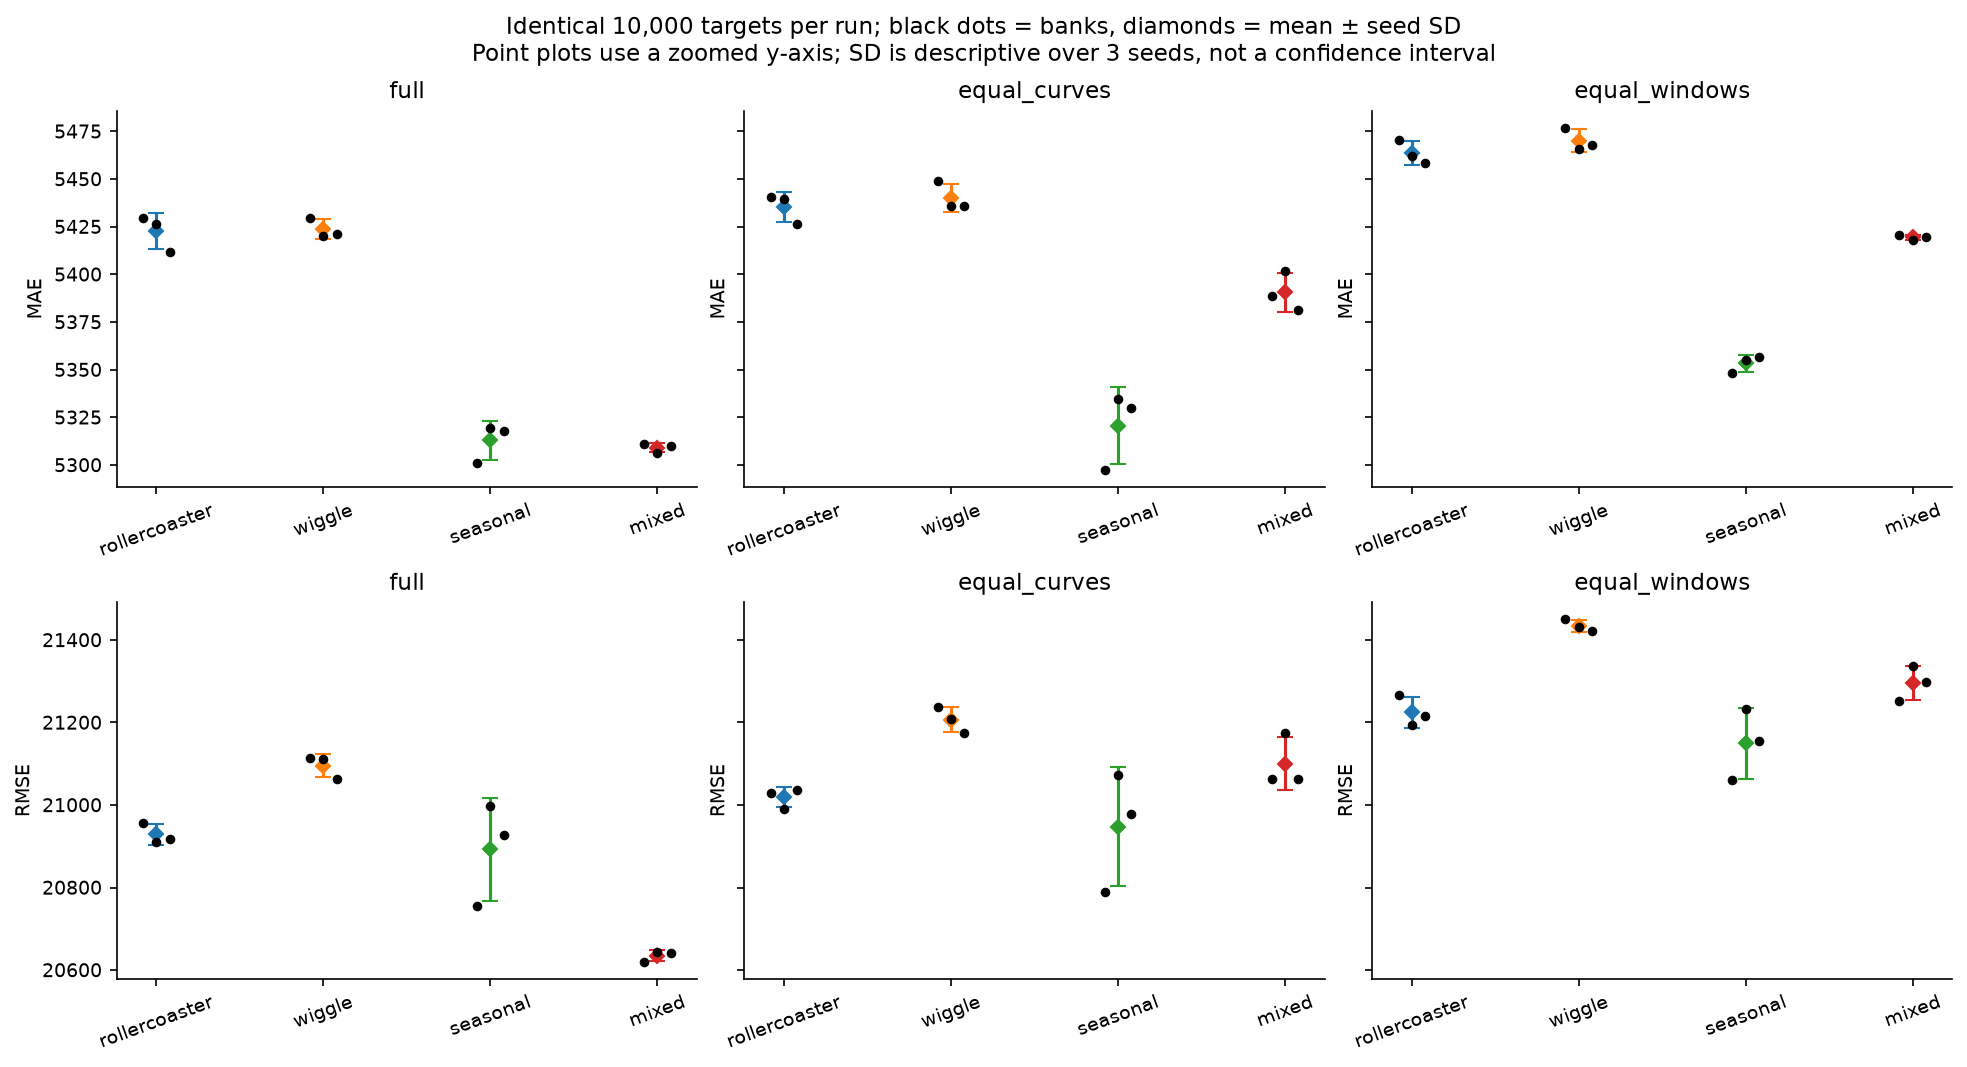

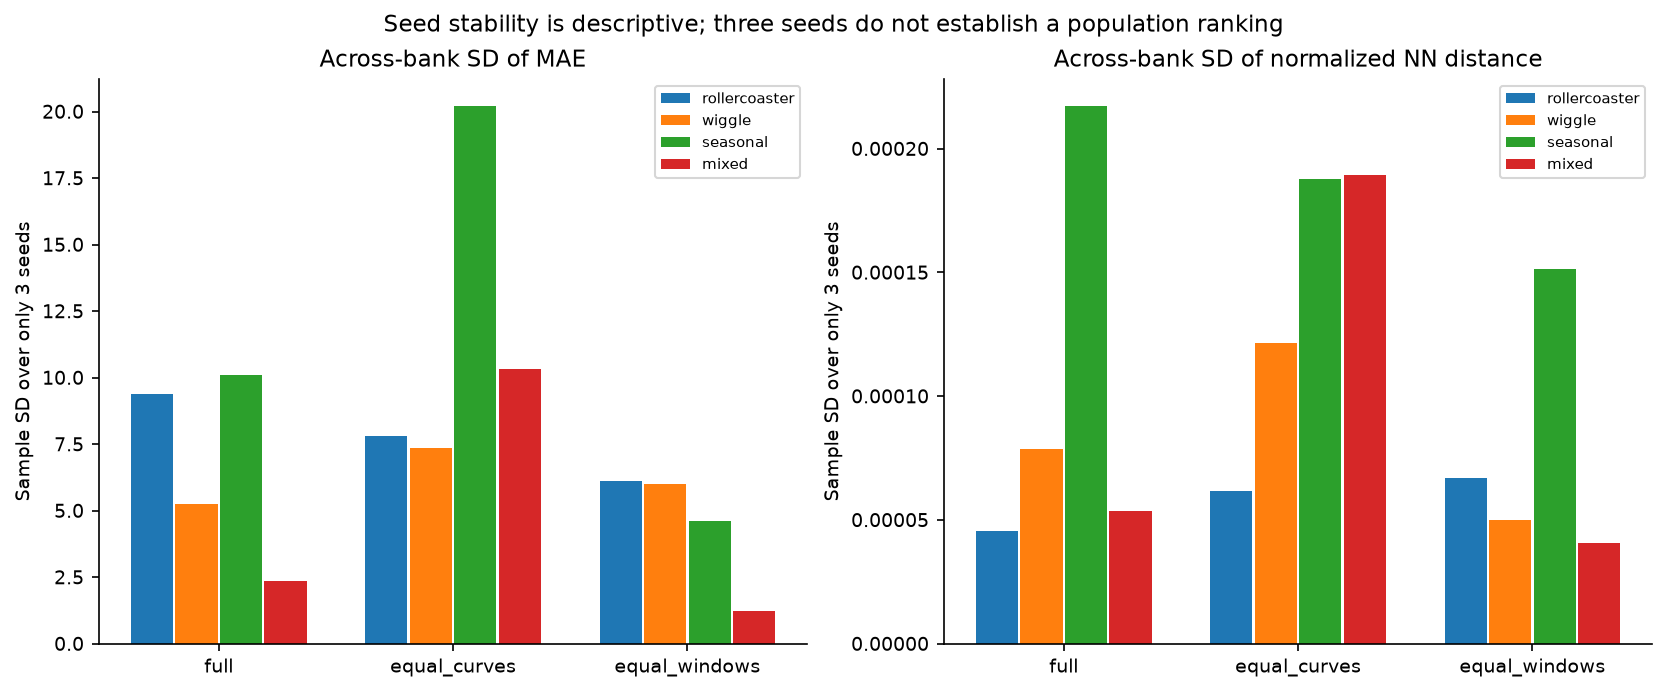

In [4]:
overall=summary.loc[summary.dimension.eq('overall')]
display(overall[['regime','library','MAE_mean','MAE_sd','RMSE_mean','RMSE_sd','normalized_MAE_mean']])
display(Image(filename=str(OUT/'figures/accuracy.png')))
display(Image(filename=str(OUT/'figures/seed_stability.png')))


## Matching quality theo thư viện

Normalized NN = minimum L1/(5 × mean last6 raw input đã floor tại 1). Chỉ chuẩn hóa khi báo cáo, không thay search hoặc input scale. Một record/state-origin/bank/config, không tăng sample size vì bốn horizons. NN thấp không bảo đảm future path tốt; đọc cùng forecast error.

,regime,library,normalized_NN_mean,normalized_NN_sd,normalized_top_m_median_mean
9,equal_curves,mixed,0.018050,0.000189,0.096038
22,equal_curves,rollercoaster,0.018039,0.000062,0.095820
35,equal_curves,seasonal,0.018568,0.000188,0.097824
48,equal_curves,wiggle,0.017981,0.000122,0.095712
61,equal_windows,mixed,0.019087,0.000041,0.103174
74,equal_windows,rollercoaster,0.019350,0.000067,0.103147
87,equal_windows,seasonal,0.019519,0.000151,0.104251
100,equal_windows,wiggle,0.019178,0.000050,0.103133
113,full,mixed,0.013942,0.000054,0.072636
126,full,rollercoaster,0.017306,0.000046,0.091622


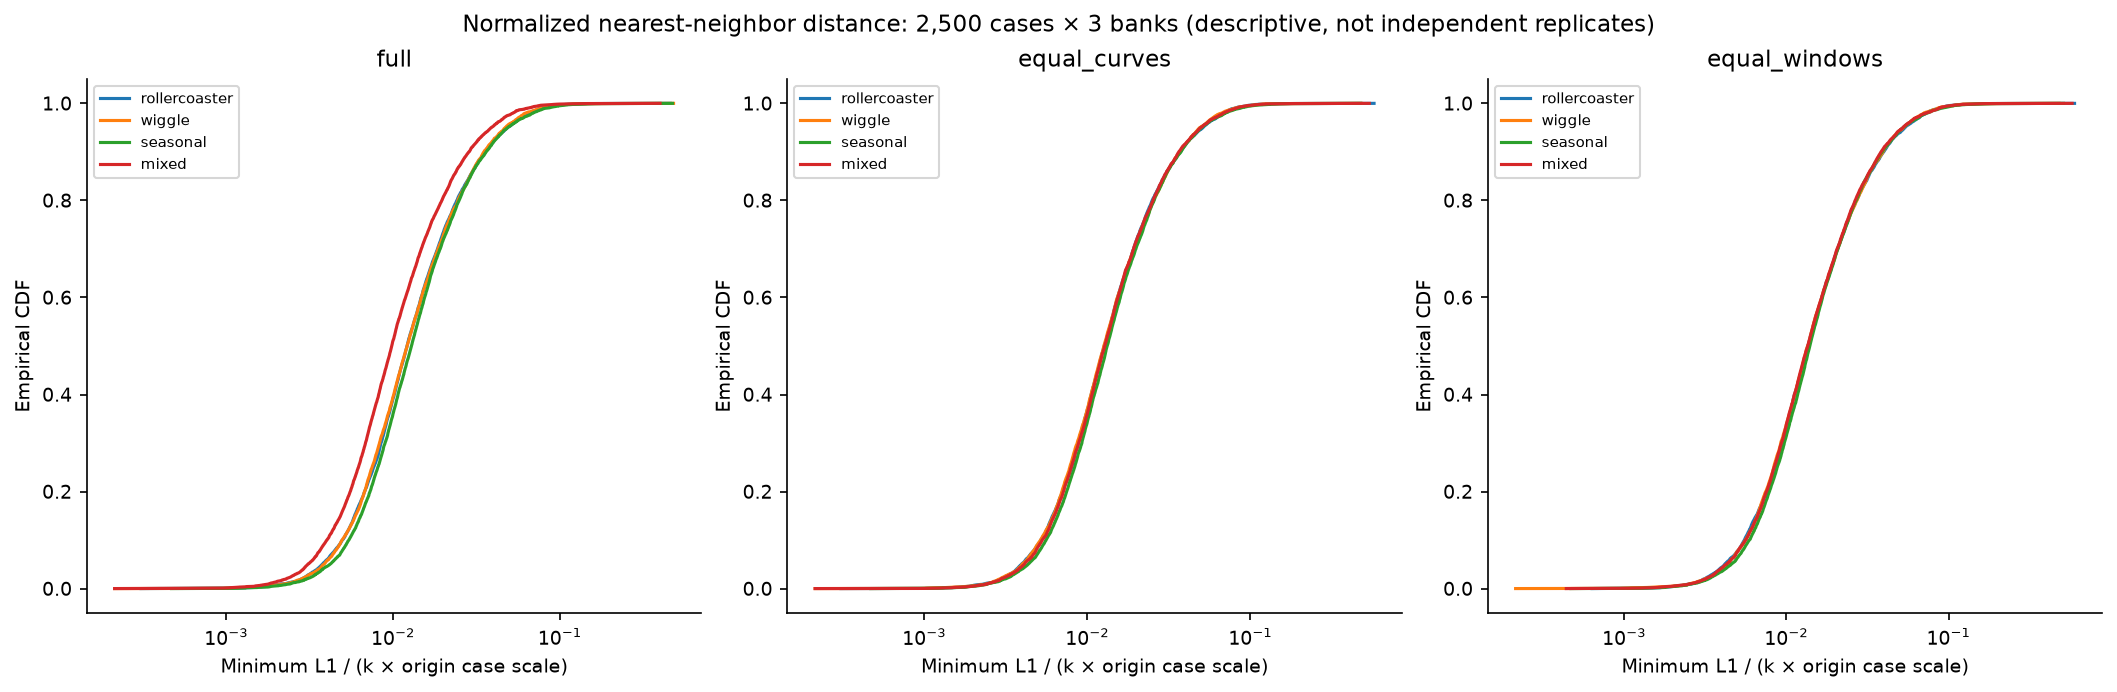

,regime,library,group,MAE,normalized_NN
0,equal_curves,mixed,declining,3322.494245,0.016946
1,equal_curves,mixed,rising,7431.696940,0.021111
2,equal_curves,mixed,stable,4455.780556,0.012760
3,equal_curves,rollercoaster,declining,3372.375368,0.017028
4,equal_curves,rollercoaster,rising,7485.843510,0.021003
5,equal_curves,rollercoaster,stable,4467.902778,0.012804
6,equal_curves,seasonal,declining,3297.234621,0.017169
7,equal_curves,seasonal,rising,7314.161873,0.021841
8,equal_curves,seasonal,stable,4414.104749,0.013334
9,equal_curves,wiggle,declining,3348.834208,0.016832


In [5]:
display(overall[['regime','library','normalized_NN_mean','normalized_NN_sd','normalized_top_m_median_mean']])
display(Image(filename=str(OUT/'figures/normalized_matching.png')))
display(scores.loc[scores.dimension.eq('phase')].groupby(['regime','library','group'],as_index=False)[['MAE','normalized_NN']].mean())


## Paired differences theo phase và horizon

Delta = MAE(single) − MAE(mixed), trong cùng regime/seed/targets; dương ưu thế mixed. CI resample nguyên bang 500 lần, giữ tất cả origins/horizons/seeds cùng cluster. CI điều kiện trên ba banks; không phải uncertainty đầy đủ qua mọi generator seeds hay mọi national waves.

,regime,library,delta_MAE,lo,hi,unique_targets,seeds
0,equal_curves,rollercoaster,44.785950,15.895360,68.971042,10000,3
13,equal_curves,seasonal,-70.021534,-116.248830,-15.732474,10000,3
26,equal_curves,wiggle,49.635083,27.453072,70.845461,10000,3
39,equal_windows,rollercoaster,44.276283,13.124345,70.321509,10000,3
52,equal_windows,seasonal,-66.210118,-107.362319,-19.569345,10000,3
65,equal_windows,wiggle,50.632633,29.621128,68.954845,10000,3
78,full,rollercoaster,113.394633,51.903935,171.752980,10000,3
91,full,seasonal,3.730183,-41.646179,54.172048,10000,3
104,full,wiggle,114.544700,57.266085,178.969439,10000,3


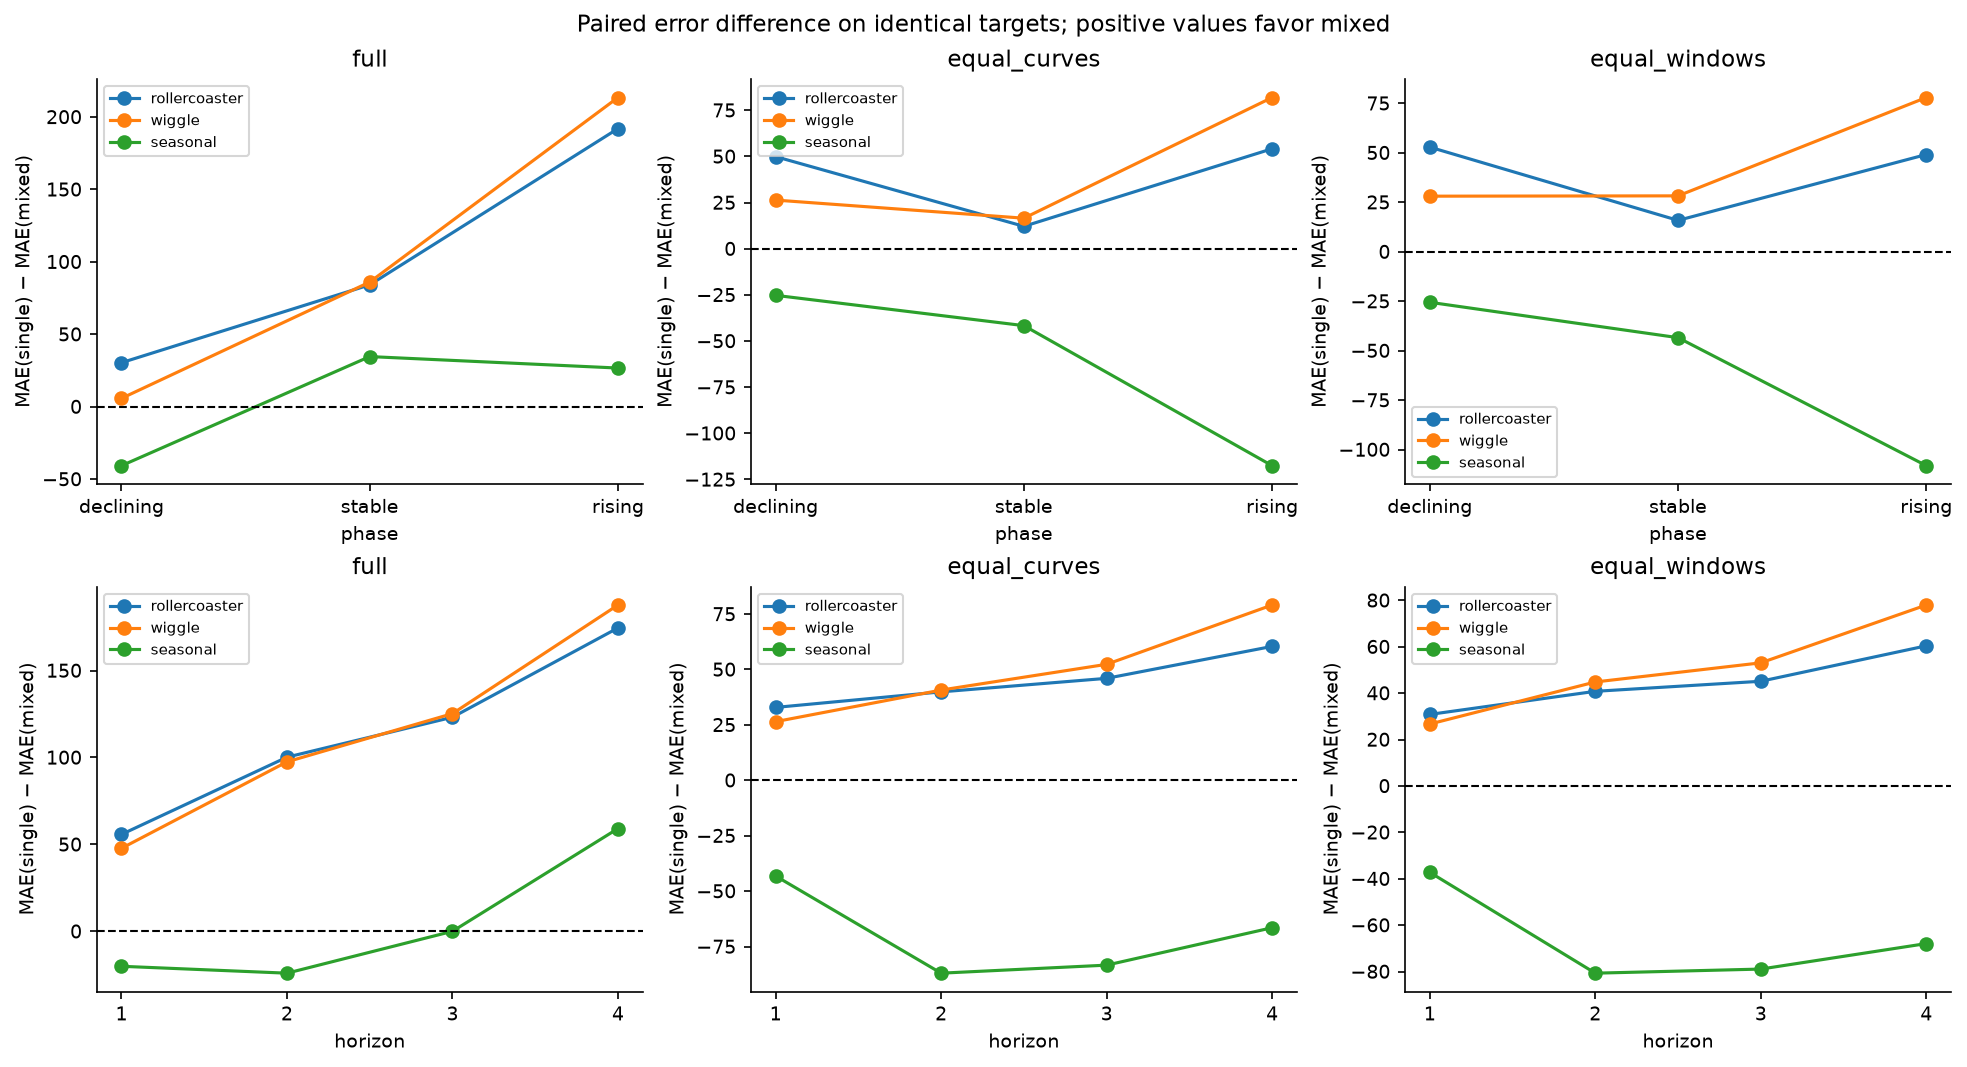

In [6]:
display(comparisons.loc[comparisons.dimension.eq('overall'),['regime','library','delta_MAE','lo','hi','unique_targets','seeds']])
display(Image(filename=str(OUT/'figures/conditional_errors.png')))


## Kiểm chứng và dữ liệu chi tiết

Giữ nguyên valid-window filter và tie-breaking của core; báo constant histories được giữ do floating-point variance, không âm thầm sửa riêng E3. Mọi input/checksums và source được đóng băng trong protocol; SQLite chứa từng forecast/match và morphology để truy vấn lại mà không xuất nhiều file trùng nhau.

In [7]:
display(pd.read_sql_query('SELECT seed,regime,library,COUNT(*) AS forecasts FROM predictions GROUP BY seed,regime,library ORDER BY seed,regime,library',db))
print('Verification:',progress.get('verification', 'See protocol/progress input checks and unit tests'))
db.close()
report=(OUT/'report.md').read_text()
display(Markdown(report.split('## Sai số và variability across seeds')[1].split('## So sánh paired')[0].split('![Accuracy]')[0]))


,seed,regime,library,forecasts
0,0,equal_curves,mixed,10000
1,0,equal_curves,rollercoaster,10000
2,0,equal_curves,seasonal,10000
3,0,equal_curves,wiggle,10000
4,0,equal_windows,mixed,10000
5,0,equal_windows,rollercoaster,10000
6,0,equal_windows,seasonal,10000
7,0,equal_windows,wiggle,10000
8,0,full,mixed,10000
9,0,full,rollercoaster,10000


Verification: {'size_controls_verified': True, 'full_family_unions_verified': True, 'reference_forecasts_reused': 30000, 'new_forecasts': 330000, 'unit_tests_passed': 9, 'database_unchanged_during_report_refresh': True, 'database_integrity': 'ok'}




| regime | library | MAE_mean | MAE_sd | RMSE_mean | RMSE_sd | normalized_NN_mean | normalized_NN_sd |
| --- | --- | --- | --- | --- | --- | --- | --- |
| equal_curves | mixed | 5,390.6451 | 10.3202 | 21,100.4797 | 64.6441 | 0.0181 | 0.0002 |
| equal_curves | rollercoaster | 5,435.4311 | 7.8109 | 21,018.9864 | 24.7927 | 0.0180 | 0.0001 |
| equal_curves | seasonal | 5,320.6236 | 20.2094 | 20,947.0391 | 144.1651 | 0.0186 | 0.0002 |
| equal_curves | wiggle | 5,440.2802 | 7.3367 | 21,206.5560 | 30.6963 | 0.0180 | 0.0001 |
| equal_windows | mixed | 5,419.4650 | 1.2380 | 21,295.7969 | 41.8573 | 0.0191 | 0.0000 |
| equal_windows | rollercoaster | 5,463.7413 | 6.1300 | 21,224.8991 | 37.5574 | 0.0194 | 0.0001 |
| equal_windows | seasonal | 5,353.2549 | 4.5988 | 21,149.1858 | 86.3165 | 0.0195 | 0.0002 |
| equal_windows | wiggle | 5,470.0976 | 5.9932 | 21,433.9517 | 14.4984 | 0.0192 | 0.0001 |
| full | mixed | 5,309.1590 | 2.3697 | 20,634.9641 | 12.6125 | 0.0139 | 0.0001 |
| full | rollercoaster | 5,422.5536 | 9.4010 | 20,928.6218 | 24.5406 | 0.0173 | 0.0000 |
| full | seasonal | 5,312.8891 | 10.0866 | 20,893.1765 | 124.9446 | 0.0180 | 0.0002 |
| full | wiggle | 5,423.7036 | 5.2632 | 21,095.6259 | 28.7077 | 0.0173 | 0.0001 |


- **full**: MAE thấp nhất trên cohort là mixed (5,309.16); SD MAE nhỏ nhất là mixed (2.37). Đây là mô tả E3, không chọn lại model từ test.
- **equal_curves**: MAE thấp nhất trên cohort là seasonal (5,320.62); SD MAE nhỏ nhất là wiggle (7.34). Đây là mô tả E3, không chọn lại model từ test.
- **equal_windows**: MAE thấp nhất trên cohort là seasonal (5,353.25); SD MAE nhỏ nhất là mixed (1.24). Đây là mô tả E3, không chọn lại model từ test.

Full seasonal−mixed chỉ **+3.73 MAE**, CI [-41.65, +54.17] chứa 0: kết quả chưa phân biệt rõ seasonal và full-mixed trên ba banks này. Khi đồng nhất curves, seasonal−mixed là **-70.02**, CI [-116.25, -15.73]; khi đồng nhất windows là **-66.21**, CI [-107.36, -19.57]. Vì thế không thể quy lợi thế full-mixed thành “trộn ba họ luôn tốt hơn”.

Relative SD của MAE qua các cấu hình nằm trong **0.023%–0.380%** trên ba seeds này. Mixed có SD nhỏ nhất ở full và equal_windows, nhưng không ở equal_curves. Seed variation nhỏ so với mức MAE không bảo đảm mọi ranking bền vững, nhất là full seasonal và mixed chỉ chênh vài ca MAE.

MAE/RMSE được tính riêng từng seed, sau đó lấy mean và sample SD của ba scores; RMSE_mean không phải pooled RMSE. Seed SD chỉ mô tả ba banks. Với hai nhánh đồng nhất kích thước, biến thiên gồm cả RNG của bank và subsampling; chưa phân rã hai nguồn này. Bộ test là chung, không có 30.000 targets độc lập chỉ vì lặp ba seeds.

